# UTS

### Cell 1 — Instalasi Library

---



Cell ini digunakan untuk menginstal library Python yang dibutuhkan dalam proses klasifikasi berita. Library yang digunakan meliputi Sastrawi untuk preprocessing teks bahasa Indonesia, Gensim untuk membangun model Skip-Gram, Scikit-learn untuk TF-IDF, Naive Bayes, pembagian data, dan evaluasi model, serta Pandas, NumPy, Matplotlib, dan Seaborn untuk pengolahan data dan visualisasi.



In [ ]:
!pip install Sastrawi gensim scikit-learn pandas numpy matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 43.5 MB/s eta 0:00:00


### Cell 2 — Import Library

---



Cell ini digunakan untuk memanggil seluruh library yang telah diinstal agar dapat digunakan dalam proses pengolahan data, preprocessing, ekstraksi fitur, klasifikasi, evaluasi, dan penyimpanan model. Sastrawi digunakan untuk menghilangkan stopword dan melakukan stemming, sedangkan Gensim digunakan untuk membuat model Word2Vec dengan metode Skip-Gram.



In [ ]:
# ==========================================
# CELL 2 - IMPORT LIBRARY
# ==========================================

import pandas as pd
import numpy as np
import re
import os
import pickle

from google.colab import files

# Sastrawi
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Scikit-learn
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Gensim untuk Skip-Gram
from gensim.models import Word2Vec

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dataset_detik_200_berita.csv to dataset_detik_200_berita (1).csv


### Cell 4 — Membaca Dataset

---


Cell ini digunakan untuk membaca dataset berita dalam format CSV menggunakan Pandas, kemudian menampilkan ukuran dataset, nama kolom, dan lima data pertama. Output menunjukkan bahwa dataset terdiri dari **200 data dan 3 kolom**, yaitu `id`, `isi_berita`, dan `label`. Kolom `id` merupakan identitas berita, `isi_berita` berisi teks berita yang akan diproses, sedangkan `label` merupakan kategori berita yang menjadi target klasifikasi.

In [ ]:
# ==========================================
# CELL 4 - MEMBACA DATASET
# ==========================================

df = pd.read_csv("dataset_detik_200_berita.csv")

print("Ukuran dataset:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\n5 data pertama:")
display(df.head())

Ukuran dataset: (200, 3)

Nama kolom:
['id', 'isi_berita', 'label']

5 data pertama:


,id,isi_berita,label
0,1,Pacuan kuda Indonesia mulai diarahkan menuju p...,sport
1,2,"Jelang Asian Games 2026, dukungan untuk 432 at...",sport
2,3,Nova Widianto mulai menangani tim ganda campur...,sport
3,4,Timnas basket putra Indonesia jadi rombongan p...,sport
4,5,"Bagi pelari urban, lari kini bukan lagi sekada...",sport


### Cell 5 — Cek Missing Value & Duplikat


---


Cell ini digunakan untuk mengecek kualitas dataset dengan melihat **missing value** dan data duplikat pada kolom `isi_berita` serta `id`. Output menunjukkan bahwa tidak terdapat missing value, duplikat isi berita, maupun duplikat ID. Artinya, dataset berisi **200 data yang lengkap dan tidak memiliki data ganda**, sehingga dapat dilanjutkan ke tahap preprocessing.

In [ ]:
# ==========================================
# CELL 5 - CEK MISSING VALUE & DUPLIKAT
# ==========================================

print("Pengecekan Dataset")
print("=" * 50)

# ------------------------------------------
# 1. Missing Value
# ------------------------------------------

print("\nJumlah Missing Value:")
print(df[["isi_berita", "label"]].isnull().sum())


# ------------------------------------------
# 2. Duplikat Isi Berita
# ------------------------------------------

print("\nJumlah Duplikat Isi Berita:")
print(df.duplicated(subset=["isi_berita"]).sum())


# ------------------------------------------
# 3. Duplikat ID
# ------------------------------------------

print("\nJumlah Duplikat ID:")
print(df["id"].duplicated().sum())

Pengecekan Dataset

Jumlah Missing Value:
isi_berita    0
label         0
dtype: int64

Jumlah Duplikat Isi Berita:
0

Jumlah Duplikat ID:
0


###  Cell 6 — Preprocessing

---



Cell ini digunakan untuk melakukan **preprocessing teks** sebelum data digunakan dalam proses klasifikasi. Tahap yang dilakukan meliputi case folding untuk mengubah huruf menjadi kecil, cleaning untuk menghapus tanda baca dan angka, stopword removal untuk menghilangkan kata-kata yang kurang penting, stemming untuk mengubah kata ke bentuk dasarnya, serta tokenisasi untuk memecah teks menjadi kata-kata. Output menunjukkan perubahan teks secara bertahap dari teks asli hingga menjadi **daftar token yang sudah diproses**, sedangkan kolom `label` tetap digunakan sebagai kategori target dan tidak ikut diproses.

In [ ]:
# ==========================================
# CELL 6 - PREPROCESSING
# ==========================================

# ------------------------------------------
# 1. Case Folding
# ------------------------------------------

df["case_folding"] = df["isi_berita"].astype(str).str.lower()


# ------------------------------------------
# 2. Cleaning
# ------------------------------------------

# Menghapus tanda baca dan karakter khusus
df["clean_text"] = df["case_folding"].apply(
    lambda x: re.sub(r"[^\w\s]", " ", x)
)

# Menghapus angka
df["clean_text"] = df["clean_text"].apply(
    lambda x: re.sub(r"\d+", " ", x)
)

# Menghapus spasi berlebih
df["clean_text"] = df["clean_text"].apply(
    lambda x: re.sub(r"\s+", " ", x).strip()
)


# ------------------------------------------
# 3. Stopword Removal
# ------------------------------------------

stop_factory = StopWordRemoverFactory()
stopword_remover = stop_factory.create_stop_word_remover()

df["text_no_stopword"] = df["clean_text"].apply(
    lambda x: stopword_remover.remove(x)
)


# ------------------------------------------
# 4. Stemming
# ------------------------------------------

stem_factory = StemmerFactory()
stemmer = stem_factory.create_stemmer()

df["text_stemmed"] = df["text_no_stopword"].apply(
    lambda x: stemmer.stem(x)
)


# ------------------------------------------
# 5. Tokenisasi
# ------------------------------------------

df["tokens_stemmed"] = df["text_stemmed"].apply(
    lambda x: x.split()
)


# ------------------------------------------
# TAMPILKAN HASIL
# ------------------------------------------

display(
    df[
        [
            "isi_berita",
            "label",
            "case_folding",
            "clean_text",
            "text_no_stopword",
            "text_stemmed",
            "tokens_stemmed"
        ]
    ].head(5)
)

,isi_berita,label,case_folding,clean_text,text_no_stopword,text_stemmed,tokens_stemmed
0,Pacuan kuda Indonesia mulai diarahkan menuju p...,sport,pacuan kuda indonesia mulai diarahkan menuju p...,pacuan kuda indonesia mulai diarahkan menuju p...,pacuan kuda indonesia mulai diarahkan menuju p...,pacu kuda indonesia mulai arah tuju panggung d...,"[pacu, kuda, indonesia, mulai, arah, tuju, pan..."
1,"Jelang Asian Games 2026, dukungan untuk 432 at...",sport,"jelang asian games 2026, dukungan untuk 432 at...",jelang asian games dukungan untuk atlet indone...,jelang asian games dukungan atlet indonesia te...,jelang asi games dukung atlet indonesia terus ...,"[jelang, asi, games, dukung, atlet, indonesia,..."
2,Nova Widianto mulai menangani tim ganda campur...,sport,nova widianto mulai menangani tim ganda campur...,nova widianto mulai menangani tim ganda campur...,nova widianto mulai menangani tim ganda campur...,nova widianto mulai tangan tim ganda campur pe...,"[nova, widianto, mulai, tangan, tim, ganda, ca..."
3,Timnas basket putra Indonesia jadi rombongan p...,sport,timnas basket putra indonesia jadi rombongan p...,timnas basket putra indonesia jadi rombongan p...,timnas basket putra indonesia jadi rombongan p...,timnas basket putra indonesia jadi rombong per...,"[timnas, basket, putra, indonesia, jadi, rombo..."
4,"Bagi pelari urban, lari kini bukan lagi sekada...",sport,"bagi pelari urban, lari kini bukan lagi sekada...",bagi pelari urban lari kini bukan lagi sekadar...,pelari urban lari kini bukan sekadar mengejar ...,lari urban lari kini bukan sekadar kejar catat...,"[lari, urban, lari, kini, bukan, sekadar, keja..."


### Cell 7 — Distribusi Label


---


Cell ini digunakan untuk melihat **distribusi jumlah data pada setiap label** dan mengetahui jumlah kelas dalam dataset. Output menunjukkan bahwa terdapat **2 kelas**, yaitu `sport` sebanyak 100 berita dan `finance` sebanyak 100 berita. Jumlah data yang sama pada kedua kelas menunjukkan bahwa dataset **seimbang**, sehingga tidak ada kelas yang lebih dominan dalam proses klasifikasi.

In [ ]:
# ==========================================
# CELL 7 - DISTRIBUSI LABEL
# ==========================================

print("Distribusi Label Berita")
print("=" * 50)

print(df["label"].value_counts())

print("\nJumlah kelas:", df["label"].nunique())

Distribusi Label Berita
label
sport      100
finance    100
Name: count, dtype: int64

Jumlah kelas: 2


### Cell 8 — Visualisasi Distribusi Label

---



Cell ini digunakan untuk menampilkan distribusi kategori berita dalam bentuk **grafik batang**. Kode `sns.countplot()` menghitung jumlah berita pada setiap kategori `label`, sedangkan `plt.title()`, `plt.xlabel()`, dan `plt.ylabel()` digunakan untuk memberikan judul serta keterangan pada grafik.

Output yang dihasilkan berupa grafik batang dengan **kategori `sport` dan `finance` pada sumbu X**, serta **jumlah berita pada sumbu Y**. Dari grafik terlihat bahwa kedua kategori memiliki jumlah yang sama, yaitu **masing-masing 100 berita**, sehingga distribusi dataset tergolong seimbang.

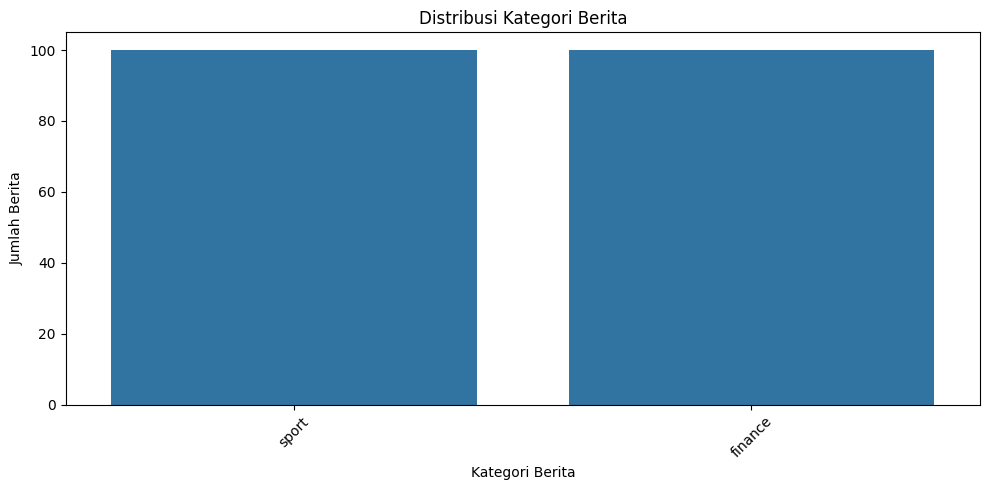

In [ ]:
# ==========================================
# CELL 8 - VISUALISASI DISTRIBUSI LABEL
# ==========================================

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="label",
    order=df["label"].value_counts().index
)

plt.title("Distribusi Kategori Berita")
plt.xlabel("Kategori Berita")
plt.ylabel("Jumlah Berita")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Cell 9 — Menentukan Data X dan y

---



Cell ini digunakan untuk menentukan **data fitur (X)** dan **target/label (y)** yang akan digunakan dalam proses klasifikasi. Variabel `X` berisi teks berita yang sudah melalui tahap preprocessing, sedangkan variabel `y` berisi kategori berita dari kolom `label`.

Output menunjukkan bahwa terdapat **200 data X dan 200 data y**, sehingga setiap berita memiliki satu teks dan satu label. Contoh X menampilkan teks berita yang sudah diproses menjadi bentuk kata dasar, sedangkan contoh y menunjukkan bahwa berita tersebut memiliki label **`sport`**.

In [ ]:
# ==========================================
# CELL 9 - MENENTUKAN X DAN y
# ==========================================

X = df["text_stemmed"].astype(str)
y = df["label"].astype(str)

print("Jumlah data X:", len(X))
print("Jumlah data y:", len(y))

print("\nContoh X:")
print(X.iloc[0][:500])

print("\nContoh y:")
print(y.iloc[0])

Jumlah data X: 200
Jumlah data y: 200

Contoh X:
pacu kuda indonesia mulai arah tuju panggung dunia lalu indonesia s horse racing ihr ini kembang sarga co konsep olahraga hibur pariwisata ekonomi kreatif ihr kembang bukan kompetisi tentu kuda cepat platform sebut rancang jadi bagi ekosistem hubung olahraga kuda potensi daerah bagai wilayah indonesia sarga co hadir bagai promotor pacu kuda profesional pertama satu satu indonesia lalu ip indonesia s horse racing hadir ihr jadi bagi upaya ubah cara pacu kuda kelola kemas kenal masyarakat olahraga

Contoh y:
sport


### Cell 10 — Pembagian Data Training dan Testing

---



Cell ini digunakan untuk membagi dataset menjadi **data training dan data testing** menggunakan `train_test_split()`. Sebanyak 80% data digunakan untuk proses pelatihan model dan 20% digunakan untuk menguji performa model. Parameter `stratify=y` digunakan agar proporsi setiap label tetap seimbang pada data training dan testing.

Output menunjukkan bahwa terdapat **160 data training** dan **40 data testing**. Data training terdiri dari 80 berita `finance` dan 80 berita `sport`, sedangkan data testing terdiri dari 20 berita `finance` dan 20 berita `sport`. Hal ini menunjukkan bahwa pembagian data tetap seimbang pada kedua kategori.

In [ ]:
# ==========================================
# CELL 10 - TRAIN TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data:")
print("Training :", len(X_train))
print("Testing  :", len(X_test))

print("\nDistribusi label training:")
print(y_train.value_counts())

print("\nDistribusi label testing:")
print(y_test.value_counts())

Jumlah data:
Training : 160
Testing  : 40

Distribusi label training:
label
finance    80
sport      80
Name: count, dtype: int64

Distribusi label testing:
label
finance    20
sport      20
Name: count, dtype: int64


### Cell 11 — Transformasi TF-IDF

---



Cell ini digunakan untuk mengubah teks berita menjadi bentuk **matriks numerik menggunakan TF-IDF**. Data training digunakan untuk membentuk vocabulary dan menghitung bobot TF-IDF, sedangkan data testing hanya ditransformasikan menggunakan vocabulary yang sudah terbentuk dari data training.

Output menunjukkan bahwa matriks TF-IDF training berukuran **(160, 4494)** dan testing berukuran **(40, 4494)**. Angka 160 dan 40 menunjukkan jumlah data, sedangkan **4494 merupakan jumlah fitur atau kata unik** yang terbentuk dari data training. Jumlah fitur pada training dan testing sama karena keduanya menggunakan vocabulary TF-IDF yang sama.

In [ ]:
# ==========================================
# CELL 11 - TF-IDF
# ==========================================

tfidf_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Ukuran matriks TF-IDF Training:")
print(X_train_tfidf.shape)

print("\nUkuran matriks TF-IDF Testing:")
print(X_test_tfidf.shape)

print("\nJumlah fitur/kata:")
print(len(tfidf_vectorizer.get_feature_names_out()))

Ukuran matriks TF-IDF Training:
(160, 4494)

Ukuran matriks TF-IDF Testing:
(40, 4494)

Jumlah fitur/kata:
4494


### Cell 12 — Training TF-IDF + Naive Bayes

---



Cell ini digunakan untuk melatih model **Naive Bayes** menggunakan data training yang sudah diubah ke bentuk matriks TF-IDF. Setelah model dilatih, model digunakan untuk memprediksi kategori pada data testing.

Output **“Training TF-IDF + Naive Bayes selesai.”** menunjukkan bahwa proses pelatihan model dan prediksi data testing telah berhasil dilakukan tanpa error. Hasil prediksi tersebut kemudian digunakan pada cell berikutnya untuk menghitung nilai accuracy, precision, recall, dan F1-score.

In [ ]:
# ==========================================
# CELL 12 - TF-IDF + NAIVE BAYES
# ==========================================

nb_tfidf = MultinomialNB()

nb_tfidf.fit(
    X_train_tfidf,
    y_train
)

# Prediksi
y_pred_tfidf = nb_tfidf.predict(X_test_tfidf)

print("Training TF-IDF + Naive Bayes selesai.")

Training TF-IDF + Naive Bayes selesai.


### Cell 13 — Evaluasi TF-IDF + Naive Bayes

---



Cell ini digunakan untuk mengevaluasi kinerja model **TF-IDF + Naive Bayes** menggunakan metrik accuracy, precision, recall, F1-score, dan classification report. Evaluasi dilakukan dengan membandingkan label sebenarnya dengan hasil prediksi pada 40 data testing.

Output menunjukkan bahwa model memperoleh **Accuracy, Precision, Recall, dan F1-Score sebesar 1.00 (100%)**. Pada classification report, kategori `finance` dan `sport` sama-sama memiliki nilai precision, recall, dan F1-score sebesar 1.00 dengan masing-masing 20 data. Artinya, seluruh **40 data testing berhasil diklasifikasikan dengan benar** oleh model TF-IDF + Naive Bayes.

In [ ]:
# ==========================================
# CELL 13 - EVALUASI TF-IDF
# ==========================================

accuracy_tfidf = accuracy_score(
    y_test,
    y_pred_tfidf
)

precision_tfidf = precision_score(
    y_test,
    y_pred_tfidf,
    average="weighted",
    zero_division=0
)

recall_tfidf = recall_score(
    y_test,
    y_pred_tfidf,
    average="weighted",
    zero_division=0
)

f1_tfidf = f1_score(
    y_test,
    y_pred_tfidf,
    average="weighted",
    zero_division=0
)

print("HASIL EVALUASI TF-IDF + NAIVE BAYES")
print("=" * 50)

print("Accuracy :", accuracy_tfidf)
print("Precision:", precision_tfidf)
print("Recall   :", recall_tfidf)
print("F1-Score :", f1_tfidf)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_tfidf,
        zero_division=0
    )
)

HASIL EVALUASI TF-IDF + NAIVE BAYES
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0

Classification Report:
              precision    recall  f1-score   support

     finance       1.00      1.00      1.00        20
       sport       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



### Cell 14 — Confusion Matrix TF-IDF

---



Cell ini digunakan untuk menampilkan hasil klasifikasi TF-IDF dan Naive Bayes dalam bentuk confusion matrix. Confusion matrix membandingkan label sebenarnya dengan label hasil prediksi model.

Output yang dihasilkan berupa tabel atau heatmap yang menunjukkan jumlah prediksi benar dan salah untuk setiap kategori. Hasil ini dapat digunakan untuk melihat kategori mana yang paling banyak berhasil maupun salah diklasifikasikan oleh model.

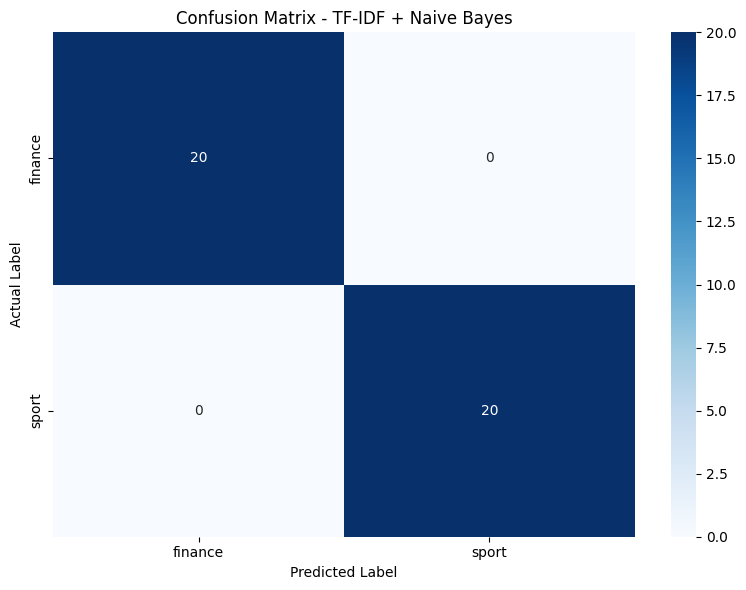

In [ ]:
# ==========================================
# CELL 14 - CONFUSION MATRIX TF-IDF
# ==========================================

cm_tfidf = confusion_matrix(
    y_test,
    y_pred_tfidf
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_tfidf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nb_tfidf.classes_,
    yticklabels=nb_tfidf.classes_
)

plt.title("Confusion Matrix - TF-IDF + Naive Bayes")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

### Cell 15 — Persiapan Token untuk Skip-Gram

---



Cell ini digunakan untuk mengambil data **token hasil preprocessing** dari data training dan testing sebagai input untuk model Skip-Gram. Data token diambil berdasarkan indeks yang sebelumnya sudah terbagi menjadi data training dan testing.

Output menunjukkan terdapat **160 dokumen training** dan **40 dokumen testing**. Contoh token menampilkan kata-kata dari salah satu berita yang sudah melalui preprocessing, seperti `perintah`, `genjot`, `energi`, dan `transisi`. Token-token tersebut nantinya digunakan untuk membangun representasi kata menggunakan metode **Skip-Gram**.

In [ ]:
# ==========================================
# CELL 15 - TOKEN UNTUK SKIP-GRAM
# ==========================================

# Mengambil index training dan testing
train_indices = X_train.index
test_indices = X_test.index

# Mengambil token berdasarkan index
tokens_train = df.loc[
    train_indices,
    "tokens_stemmed"
].tolist()

tokens_test = df.loc[
    test_indices,
    "tokens_stemmed"
].tolist()

print("Jumlah dokumen training:", len(tokens_train))
print("Jumlah dokumen testing :", len(tokens_test))

print("\nContoh token:")
print(tokens_train[0][:20])

Jumlah dokumen training: 160
Jumlah dokumen testing : 40

Contoh token:
['perintah', 'terus', 'genjot', 'kembang', 'energi', 'baru', 'baru', 'konservasi', 'energi', 'ebtke', 'bagi', 'upaya', 'cepat', 'transisi', 'tuju', 'sistem', 'energi', 'lebih', 'bersih', 'bagai']


### Cell 16 — Training Model Skip-Gram

Cell ini digunakan untuk melatih model **Word2Vec dengan metode Skip-Gram** berdasarkan token dari data training. Parameter `sg=1` menunjukkan bahwa Word2Vec menggunakan metode Skip-Gram, sedangkan `vector_size=100` menentukan jumlah dimensi vektor untuk setiap kata.

Output menunjukkan bahwa proses training Skip-Gram berhasil. Vocabulary yang terbentuk terdiri dari **4.514 kata**, sedangkan setiap kata direpresentasikan dalam **vektor berukuran 100 dimensi**. Vektor ini nantinya digunakan untuk membentuk representasi numerik dari setiap dokumen berita.

In [ ]:
# ==========================================
# CELL 16 - TRAINING SKIP-GRAM
# ==========================================

skipgram_model = Word2Vec(
    sentences=tokens_train,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=1,
    epochs=20,
    seed=42
)

print("Training Skip-Gram selesai.")

print("\nJumlah kata dalam vocabulary:",
      len(skipgram_model.wv))

print("Ukuran vector:",
      skipgram_model.vector_size)

Training Skip-Gram selesai.

Jumlah kata dalam vocabulary: 4514
Ukuran vector: 100


### Cell 17 — Membentuk Vektor Dokumen Skip-Gram

---



Cell ini digunakan untuk mengubah setiap dokumen berita menjadi **vektor numerik** berdasarkan vektor kata yang dihasilkan oleh model Skip-Gram. Vektor setiap kata dalam satu dokumen dirata-ratakan sehingga menghasilkan satu representasi vektor untuk setiap berita.

Output menunjukkan bahwa matriks Skip-Gram pada data training berukuran **(160, 100)** dan data testing berukuran **(40, 100)**. Angka 160 dan 40 menunjukkan jumlah dokumen, sedangkan **100 merupakan jumlah dimensi vektor** yang digunakan untuk merepresentasikan setiap dokumen.

In [ ]:
# ==========================================
# CELL 17 - MEMBUAT DOCUMENT VECTOR
# ==========================================

def document_vector(model, tokens):
    vectors = []

    for word in tokens:
        if word in model.wv:
            vectors.append(model.wv[word])

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


# Membuat vector training
X_train_skipgram = np.array([
    document_vector(skipgram_model, tokens)
    for tokens in tokens_train
])


# Membuat vector testing
X_test_skipgram = np.array([
    document_vector(skipgram_model, tokens)
    for tokens in tokens_test
])


print("Ukuran matriks Skip-Gram Training:")
print(X_train_skipgram.shape)

print("\nUkuran matriks Skip-Gram Testing:")
print(X_test_skipgram.shape)

Ukuran matriks Skip-Gram Training:
(160, 100)

Ukuran matriks Skip-Gram Testing:
(40, 100)


### Cell 18 — Scaling Vektor Skip-Gram

---



Cell ini digunakan untuk melakukan **normalisasi nilai vektor Skip-Gram** menggunakan `MinMaxScaler`. Proses ini mengubah nilai setiap fitur ke rentang sekitar **0 sampai 1**, sehingga data lebih sesuai untuk digunakan sebagai input model Naive Bayes.

Output menunjukkan bahwa proses scaling berhasil dilakukan. Nilai minimum training adalah **0.0**, sedangkan nilai maksimum **1.0000001**, yang secara praktis menunjukkan bahwa nilai fitur telah berada pada rentang **0–1**.

In [ ]:
# ==========================================
# CELL 18 - SCALING SKIP-GRAM
# ==========================================

scaler_skipgram = MinMaxScaler()

X_train_skipgram_scaled = scaler_skipgram.fit_transform(
    X_train_skipgram
)

X_test_skipgram_scaled = scaler_skipgram.transform(
    X_test_skipgram
)

print("Scaling Skip-Gram selesai.")

print("\nNilai minimum training:",
      X_train_skipgram_scaled.min())

print("Nilai maksimum training:",
      X_train_skipgram_scaled.max())

Scaling Skip-Gram selesai.

Nilai minimum training: 0.0
Nilai maksimum training: 1.0000001


### Cell 19 — Training Skip-Gram + Naive Bayes

---



Cell ini digunakan untuk melatih model **Naive Bayes** menggunakan vektor dokumen yang telah dihasilkan dari Skip-Gram dan sudah melalui proses scaling. Setelah model dilatih, model digunakan untuk melakukan prediksi terhadap data testing.

Output **“Training Skip-Gram + Naive Bayes selesai.”** menunjukkan bahwa proses pelatihan model dan prediksi data testing berhasil dilakukan tanpa error. Hasil prediksi tersebut selanjutnya digunakan untuk mengevaluasi performa model pada Cell 20.

In [ ]:
# ==========================================
# CELL 19 - SKIP-GRAM + NAIVE BAYES
# ==========================================

nb_skipgram = MultinomialNB()

nb_skipgram.fit(
    X_train_skipgram_scaled,
    y_train
)

# Prediksi
y_pred_skipgram = nb_skipgram.predict(
    X_test_skipgram_scaled
)

print("Training Skip-Gram + Naive Bayes selesai.")

Training Skip-Gram + Naive Bayes selesai.


### Cell 20 — Evaluasi Skip-Gram + Naive Bayes

---



Cell ini digunakan untuk mengevaluasi performa model **Skip-Gram + Naive Bayes** menggunakan metrik accuracy, precision, recall, F1-score, dan classification report. Evaluasi dilakukan berdasarkan hasil prediksi terhadap 40 data testing.

Output menunjukkan bahwa model memperoleh **Accuracy, Precision, Recall, dan F1-Score sebesar 1.00 (100%)**. Kategori `finance` dan `sport` masing-masing memiliki nilai precision, recall, dan F1-score sebesar 1.00 dengan 20 data. Artinya, seluruh **40 data testing berhasil diklasifikasikan dengan benar** oleh model Skip-Gram + Naive Bayes.

In [ ]:
# ==========================================
# CELL 20 - EVALUASI SKIP-GRAM
# ==========================================

accuracy_skipgram = accuracy_score(
    y_test,
    y_pred_skipgram
)

precision_skipgram = precision_score(
    y_test,
    y_pred_skipgram,
    average="weighted",
    zero_division=0
)

recall_skipgram = recall_score(
    y_test,
    y_pred_skipgram,
    average="weighted",
    zero_division=0
)

f1_skipgram = f1_score(
    y_test,
    y_pred_skipgram,
    average="weighted",
    zero_division=0
)

print("HASIL EVALUASI SKIP-GRAM + NAIVE BAYES")
print("=" * 50)

print("Accuracy :", accuracy_skipgram)
print("Precision:", precision_skipgram)
print("Recall   :", recall_skipgram)
print("F1-Score :", f1_skipgram)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_skipgram,
        zero_division=0
    )
)

HASIL EVALUASI SKIP-GRAM + NAIVE BAYES
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0

Classification Report:
              precision    recall  f1-score   support

     finance       1.00      1.00      1.00        20
       sport       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



### Cell 21 — Confusion Matrix Skip-Gram

---



Cell ini digunakan untuk menampilkan hasil prediksi model Skip-Gram dan Naive Bayes dalam bentuk confusion matrix. Confusion matrix digunakan untuk mengetahui jumlah prediksi yang benar dan salah pada setiap kategori berita.

Output yang dihasilkan berupa heatmap confusion matrix yang membandingkan label sebenarnya dengan label hasil prediksi. Hasil ini dapat digunakan untuk melihat pola kesalahan klasifikasi yang dilakukan oleh model.

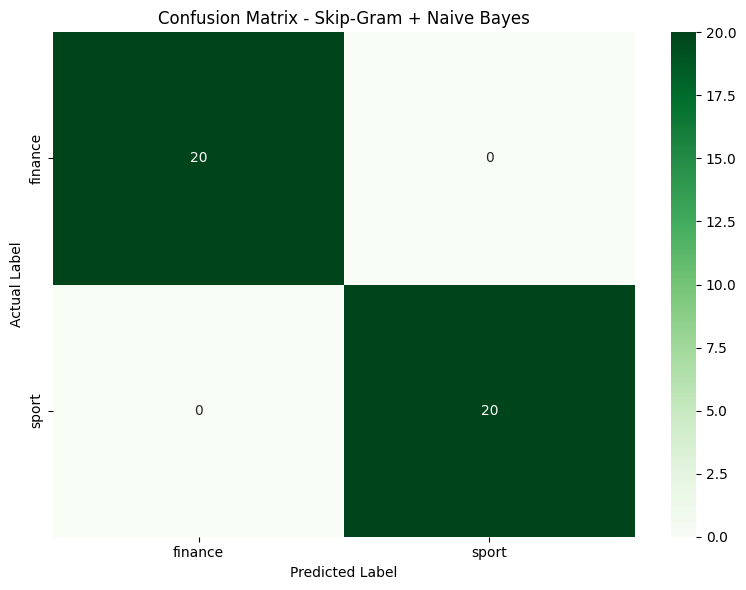

In [ ]:
# ==========================================
# CELL 21 - CONFUSION MATRIX SKIP-GRAM
# ==========================================

cm_skipgram = confusion_matrix(
    y_test,
    y_pred_skipgram
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_skipgram,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=nb_skipgram.classes_,
    yticklabels=nb_skipgram.classes_
)

plt.title("Confusion Matrix - Skip-Gram + Naive Bayes")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

### Cell 22 — Perbandingan TF-IDF dan Skip-Gram

---



Cell ini digunakan untuk membandingkan performa **TF-IDF + Naive Bayes** dan **Skip-Gram + Naive Bayes** berdasarkan nilai accuracy, precision, recall, dan F1-score. Hasil dari kedua metode disusun dalam bentuk tabel agar lebih mudah dibandingkan.

Output menunjukkan bahwa kedua metode memperoleh **Accuracy, Precision, Recall, dan F1-Score sebesar 1.00 (100%)**. Artinya, pada data testing yang digunakan, kedua metode memiliki performa yang sama dan berhasil mengklasifikasikan seluruh data dengan benar.

In [ ]:
# ==========================================
# CELL 22 - PERBANDINGAN HASIL
# ==========================================

hasil_perbandingan = pd.DataFrame({
    "Metode": [
        "TF-IDF + Naive Bayes",
        "Skip-Gram + Naive Bayes"
    ],
    "Accuracy": [
        accuracy_tfidf,
        accuracy_skipgram
    ],
    "Precision": [
        precision_tfidf,
        precision_skipgram
    ],
    "Recall": [
        recall_tfidf,
        recall_skipgram
    ],
    "F1-Score": [
        f1_tfidf,
        f1_skipgram
    ]
})

display(hasil_perbandingan)

,Metode,Accuracy,Precision,Recall,F1-Score
0,TF-IDF + Naive Bayes,1.0,1.0,1.0,1.0
1,Skip-Gram + Naive Bayes,1.0,1.0,1.0,1.0


### Cell 23 — Perbandingan Ukuran Space

---



Cell ini digunakan untuk membandingkan **ukuran representasi data (space)** antara metode TF-IDF dan Skip-Gram. Ukuran tersebut dilihat dari jumlah data dan jumlah fitur atau dimensi yang dihasilkan oleh masing-masing metode.

Output menunjukkan bahwa TF-IDF menghasilkan matriks training berukuran **(160, 4494)** dan testing **(40, 4494)**, sedangkan Skip-Gram menghasilkan ukuran **(160, 100)** dan **(40, 100)**. Artinya, TF-IDF menggunakan **4.494 fitur**, sementara Skip-Gram hanya menggunakan **100 dimensi vektor** untuk merepresentasikan setiap dokumen. Selain itu, matriks embedding Skip-Gram berukuran **(4514, 100)**, yang berarti terdapat **4.514 kata dalam vocabulary**, dengan masing-masing kata direpresentasikan menggunakan 100 dimensi.

In [ ]:
# ==========================================
# CELL 23 - PERBANDINGAN UKURAN SPACE
# ==========================================

print("PERBANDINGAN UKURAN SPACE")
print("=" * 50)

print("TF-IDF")
print("Training :", X_train_tfidf.shape)
print("Testing  :", X_test_tfidf.shape)

print("\nSkip-Gram")
print("Training :", X_train_skipgram.shape)
print("Testing  :", X_test_skipgram.shape)

print("\nWord Embedding Matrix Skip-Gram:")
print(skipgram_model.wv.vectors.shape)

PERBANDINGAN UKURAN SPACE
TF-IDF
Training : (160, 4494)
Testing  : (40, 4494)

Skip-Gram
Training : (160, 100)
Testing  : (40, 100)

Word Embedding Matrix Skip-Gram:
(4514, 100)


### Cell 24 — Menentukan Parameter Grid Search

---



Cell ini digunakan untuk menentukan beberapa kombinasi parameter yang akan diuji pada proses **Grid Search** untuk model Skip-Gram dan Naive Bayes. Parameter yang diuji meliputi `vector_size`, `window`, `min_count`, `epochs`, dan `alpha`.

Output menunjukkan **24 kombinasi parameter** yang akan dicoba. Setiap kombinasi nantinya digunakan untuk melatih dan mengevaluasi model, sehingga dapat diketahui kombinasi parameter yang menghasilkan performa terbaik.

In [ ]:
# ==========================================
# CELL 24 - GRID SEARCH SKIP-GRAM
# ==========================================

param_grid = {
    "vector_size": [50, 100],
    "window": [3, 5],
    "min_count": [1],
    "epochs": [10, 20],
    "alpha": [0.1, 0.5, 1.0]
}

grid = list(ParameterGrid(param_grid))

print("Jumlah kombinasi parameter:", len(grid))

Jumlah kombinasi parameter: 24


### Cell 25 — Proses Grid Search

---



Cell ini digunakan untuk menjalankan **Grid Search** dengan mencoba seluruh kombinasi parameter yang telah ditentukan pada Cell 24. Setiap kombinasi digunakan untuk melatih model Skip-Gram dan Naive Bayes, kemudian performanya dihitung menggunakan accuracy, precision, recall, dan F1-score.

Output menunjukkan bahwa sistem telah melakukan **24 percobaan**, mulai dari percobaan 1 hingga 24, dengan variasi `vector_size`, `window`, `epochs`, dan `alpha`. Pesan **“Grid Search selesai.”** menunjukkan bahwa seluruh 24 kombinasi parameter telah berhasil diuji dan hasilnya disimpan untuk dibandingkan pada cell berikutnya.

In [ ]:
# ==========================================
# CELL 25 - PROSES GRID SEARCH
# ==========================================

hasil_grid = []

for i, params in enumerate(grid, start=1):

    print(
        f"Percobaan {i}/{len(grid)} | "
        f"vector_size={params['vector_size']}, "
        f"window={params['window']}, "
        f"min_count={params['min_count']}, "
        f"epochs={params['epochs']}, "
        f"alpha={params['alpha']}"
    )

    # --------------------------------------
    # Training Skip-Gram
    # --------------------------------------

    model = Word2Vec(
        sentences=tokens_train,
        vector_size=params["vector_size"],
        window=params["window"],
        min_count=params["min_count"],
        workers=4,
        sg=1,
        epochs=params["epochs"],
        seed=42
    )

    # --------------------------------------
    # Document Vector
    # --------------------------------------

    train_vectors = np.array([
        document_vector(model, tokens)
        for tokens in tokens_train
    ])

    test_vectors = np.array([
        document_vector(model, tokens)
        for tokens in tokens_test
    ])

    # --------------------------------------
    # Scaling
    # --------------------------------------

    scaler = MinMaxScaler()

    train_scaled = scaler.fit_transform(train_vectors)
    test_scaled = scaler.transform(test_vectors)

    # --------------------------------------
    # Naive Bayes
    # --------------------------------------

    model_nb = MultinomialNB(
        alpha=params["alpha"]
    )

    model_nb.fit(
        train_scaled,
        y_train
    )

    # --------------------------------------
    # Prediksi
    # --------------------------------------

    pred = model_nb.predict(test_scaled)

    # --------------------------------------
    # Evaluasi
    # --------------------------------------

    accuracy = accuracy_score(
        y_test,
        pred
    )

    precision = precision_score(
        y_test,
        pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        pred,
        average="weighted",
        zero_division=0
    )

    hasil_grid.append({
        "vector_size": params["vector_size"],
        "window": params["window"],
        "min_count": params["min_count"],
        "epochs": params["epochs"],
        "alpha": params["alpha"],
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    })


print("\nGrid Search selesai.")

Percobaan 1/24 | vector_size=50, window=3, min_count=1, epochs=10, alpha=0.1
Percobaan 2/24 | vector_size=50, window=5, min_count=1, epochs=10, alpha=0.1
Percobaan 3/24 | vector_size=100, window=3, min_count=1, epochs=10, alpha=0.1
Percobaan 4/24 | vector_size=100, window=5, min_count=1, epochs=10, alpha=0.1
Percobaan 5/24 | vector_size=50, window=3, min_count=1, epochs=20, alpha=0.1
Percobaan 6/24 | vector_size=50, window=5, min_count=1, epochs=20, alpha=0.1
Percobaan 7/24 | vector_size=100, window=3, min_count=1, epochs=20, alpha=0.1
Percobaan 8/24 | vector_size=100, window=5, min_count=1, epochs=20, alpha=0.1
Percobaan 9/24 | vector_size=50, window=3, min_count=1, epochs=10, alpha=0.5
Percobaan 10/24 | vector_size=50, window=5, min_count=1, epochs=10, alpha=0.5
Percobaan 11/24 | vector_size=100, window=3, min_count=1, epochs=10, alpha=0.5
Percobaan 12/24 | vector_size=100, window=5, min_count=1, epochs=10, alpha=0.5
Percobaan 13/24 | vector_size=50, window=3, min_count=1, epochs=20,

### Cell 26 — Hasil Grid Search

---



Cell ini digunakan untuk menampilkan dan mengurutkan hasil dari seluruh kombinasi parameter yang telah diuji pada proses Grid Search berdasarkan nilai **F1-Score** dari yang tertinggi ke terendah. Tabel menampilkan parameter yang digunakan serta hasil evaluasi setiap kombinasi.

Output menunjukkan bahwa seluruh **24 kombinasi parameter** menghasilkan nilai **Accuracy, Precision, Recall, dan F1-Score sebesar 1.00 (100%)**. Artinya, semua kombinasi parameter yang diuji memiliki performa yang sama pada data testing, sehingga tidak terdapat satu kombinasi yang lebih unggul berdasarkan nilai F1-Score.

In [ ]:
# ==========================================
# CELL 26 - HASIL GRID SEARCH
# ==========================================

hasil_grid_df = pd.DataFrame(hasil_grid)

hasil_grid_df = hasil_grid_df.sort_values(
    by="f1_score",
    ascending=False
).reset_index(drop=True)

display(hasil_grid_df)

,vector_size,window,min_count,epochs,alpha,accuracy,precision,recall,f1_score
0,50,3,1,10,0.1,1.0,1.0,1.0,1.0
1,50,5,1,10,0.1,1.0,1.0,1.0,1.0
2,100,3,1,10,0.1,1.0,1.0,1.0,1.0
3,100,5,1,10,0.1,1.0,1.0,1.0,1.0
4,50,3,1,20,0.1,1.0,1.0,1.0,1.0
5,50,5,1,20,0.1,1.0,1.0,1.0,1.0
6,100,3,1,20,0.1,1.0,1.0,1.0,1.0
7,100,5,1,20,0.1,1.0,1.0,1.0,1.0
8,50,3,1,10,0.5,1.0,1.0,1.0,1.0
9,50,5,1,10,0.5,1.0,1.0,1.0,1.0


### Cell 27 — Menentukan Parameter Terbaik

---



Cell ini digunakan untuk mengambil **kombinasi parameter terbaik** berdasarkan hasil Grid Search pada Cell 26. Parameter terbaik dipilih berdasarkan nilai **F1-Score tertinggi**, karena F1-Score mempertimbangkan keseimbangan antara precision dan recall.

Output menunjukkan bahwa parameter yang dipilih adalah **vector size 50, window 3, min count 1, epochs 10, dan alpha 0.1**. Kombinasi tersebut memperoleh **Accuracy, Precision, Recall, dan F1-Score sebesar 1.00 (100%)**. Namun, karena seluruh kombinasi menghasilkan nilai yang sama, parameter tersebut merupakan kombinasi pertama yang terpilih dari hasil Grid Search, bukan satu-satunya kombinasi terbaik.

In [ ]:
# ==========================================
# CELL 27 - PARAMETER TERBAIK
# ==========================================

best_params = hasil_grid_df.iloc[0]

print("PARAMETER TERBAIK")
print("=" * 50)

print("Vector Size :", best_params["vector_size"])
print("Window      :", best_params["window"])
print("Min Count   :", best_params["min_count"])
print("Epochs      :", best_params["epochs"])
print("Alpha       :", best_params["alpha"])

print("\nHASIL TERBAIK")
print("Accuracy    :", best_params["accuracy"])
print("Precision   :", best_params["precision"])
print("Recall      :", best_params["recall"])
print("F1-Score    :", best_params["f1_score"])

PARAMETER TERBAIK
Vector Size : 50.0
Window      : 3.0
Min Count   : 1.0
Epochs      : 10.0
Alpha       : 0.1

HASIL TERBAIK
Accuracy    : 1.0
Precision   : 1.0
Recall      : 1.0
F1-Score    : 1.0


### Cell 28 — Melatih Model Final Skip-Gram + Naive Bayes

---



Cell ini digunakan untuk **membangun dan melatih model final** menggunakan parameter yang telah dipilih dari hasil Grid Search pada Cell 27. Model Skip-Gram dibuat dengan parameter terbaik, kemudian setiap dokumen diubah menjadi vektor berdasarkan rata-rata word embedding. Selanjutnya, vektor tersebut dinormalisasi menggunakan `MinMaxScaler` dan digunakan sebagai input untuk model **Naive Bayes**.

Output **"Model final berhasil dilatih."** menunjukkan bahwa seluruh proses pembentukan model Skip-Gram, transformasi data, scaling, hingga pelatihan **Naive Bayes** berhasil dilakukan tanpa error. Model final ini nantinya digunakan untuk evaluasi dan disimpan sebagai file `.pkl`.

In [ ]:
# ==========================================
# CELL 28 - TRAINING MODEL FINAL
# ==========================================

best_vector_size = int(best_params["vector_size"])
best_window = int(best_params["window"])
best_min_count = int(best_params["min_count"])
best_epochs = int(best_params["epochs"])
best_alpha = float(best_params["alpha"])


# ------------------------------------------
# Skip-Gram Final
# ------------------------------------------

final_skipgram = Word2Vec(
    sentences=tokens_train,
    vector_size=best_vector_size,
    window=best_window,
    min_count=best_min_count,
    workers=4,
    sg=1,
    epochs=best_epochs,
    seed=42
)


# ------------------------------------------
# Document Vector
# ------------------------------------------

final_X_train = np.array([
    document_vector(final_skipgram, tokens)
    for tokens in tokens_train
])

final_X_test = np.array([
    document_vector(final_skipgram, tokens)
    for tokens in tokens_test
])


# ------------------------------------------
# Scaling
# ------------------------------------------

final_scaler = MinMaxScaler()

final_X_train_scaled = final_scaler.fit_transform(
    final_X_train
)

final_X_test_scaled = final_scaler.transform(
    final_X_test
)


# ------------------------------------------
# Naive Bayes Final
# ------------------------------------------

final_nb = MultinomialNB(
    alpha=best_alpha
)

final_nb.fit(
    final_X_train_scaled,
    y_train
)


# ------------------------------------------
# Prediksi
# ------------------------------------------

final_pred = final_nb.predict(
    final_X_test_scaled
)

print("Model final berhasil dilatih.")

Model final berhasil dilatih.


### Cell 29 — Evaluasi Model Final

---



Cell ini digunakan untuk **mengukur performa model final** yang telah dilatih pada Cell 28 menggunakan data testing. Evaluasi dilakukan dengan menghitung **Accuracy, Precision, Recall, dan F1-Score**, serta menampilkan **Classification Report** untuk melihat performa model pada masing-masing kelas.

Output menunjukkan bahwa model final memperoleh **Accuracy, Precision, Recall, dan F1-Score sebesar 1.00 atau 100%**. Pada kelas **finance** dan **sport**, seluruh nilai precision, recall, dan f1-score juga sebesar 1.00 dengan masing-masing 20 data testing. Artinya, dari total **40 data testing, seluruh data berhasil diklasifikasikan dengan benar** oleh model Skip-Gram + Naive Bayes.

Nilai **macro avg** dan **weighted avg** yang sama-sama 1.00 menunjukkan bahwa performa model pada kedua kelas seimbang. Dengan demikian, berdasarkan data testing yang digunakan, model final memiliki hasil klasifikasi yang sangat baik.

In [ ]:
# ==========================================
# CELL 29 - EVALUASI MODEL FINAL
# ==========================================

final_accuracy = accuracy_score(
    y_test,
    final_pred
)

final_precision = precision_score(
    y_test,
    final_pred,
    average="weighted",
    zero_division=0
)

final_recall = recall_score(
    y_test,
    final_pred,
    average="weighted",
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    final_pred,
    average="weighted",
    zero_division=0
)

print("HASIL MODEL FINAL")
print("=" * 50)

print("Accuracy :", final_accuracy)
print("Precision:", final_precision)
print("Recall   :", final_recall)
print("F1-Score :", final_f1)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_pred,
        zero_division=0
    )
)

HASIL MODEL FINAL
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0

Classification Report:
              precision    recall  f1-score   support

     finance       1.00      1.00      1.00        20
       sport       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



### Cell 30 — Menyimpan Model Skip-Gram

---



Cell ini digunakan untuk **menyimpan model Skip-Gram yang telah dilatih** ke dalam file dengan format `.pkl` menggunakan library `pickle`. Model disimpan dengan nama `skipgram_model.pkl` agar nantinya dapat digunakan kembali tanpa perlu melakukan proses training dari awal.

Output **"skipgram_model.pkl berhasil disimpan."** menunjukkan bahwa model Skip-Gram berhasil disimpan ke dalam file.


In [ ]:
# ==========================================
# CELL 30 - SIMPAN MODEL SKIP-GRAM
# ==========================================

with open("skipgram_model.pkl", "wb") as file:
    pickle.dump(final_skipgram, file)

print("skipgram_model.pkl berhasil disimpan.")

skipgram_model.pkl berhasil disimpan.


### Cell 31 — Menyimpan Model Naive Bayes

---



Cell ini digunakan untuk **menyimpan model Naive Bayes** yang telah dilatih menggunakan hasil representasi Skip-Gram. Model disimpan dalam file `naive_bayes_skipgram.pkl`.

Output **"naive_bayes_skipgram.pkl berhasil disimpan."** menunjukkan bahwa model Naive Bayes berhasil disimpan dan siap digunakan kembali untuk proses klasifikasi.

In [ ]:
# ==========================================
# CELL 31 - SIMPAN MODEL NAIVE BAYES
# ==========================================

with open("naive_bayes_skipgram.pkl", "wb") as file:
    pickle.dump(final_nb, file)

print("naive_bayes_skipgram.pkl berhasil disimpan.")

naive_bayes_skipgram.pkl berhasil disimpan.




### Cell 32 — Menyimpan Scaler

---



Cell ini digunakan untuk **menyimpan `MinMaxScaler`** yang sebelumnya digunakan untuk melakukan normalisasi nilai vektor Skip-Gram. Scaler disimpan dalam file `scaler_skipgram.pkl`.

Scaler perlu disimpan karena ketika model digunakan kembali untuk melakukan prediksi pada data baru, data tersebut harus melalui proses scaling dengan aturan yang sama seperti data training.

Output **"scaler_skipgram.pkl berhasil disimpan."** menunjukkan bahwa scaler berhasil disimpan.

In [ ]:
# ==========================================
# CELL 32 - SIMPAN SCALER
# ==========================================

with open("scaler_skipgram.pkl", "wb") as file:
    pickle.dump(final_scaler, file)

print("scaler_skipgram.pkl berhasil disimpan.")

scaler_skipgram.pkl berhasil disimpan.


### Cell 33 — Mengunduh File Model

---



Cell ini digunakan untuk **mengunduh ketiga file model** yang telah disimpan dari Google Colab ke komputer, yaitu:

- `skipgram_model.pkl` → model Skip-Gram.
- `naive_bayes_skipgram.pkl` → model Naive Bayes untuk klasifikasi.
- `scaler_skipgram.pkl` → scaler untuk normalisasi data.

Ketiga file tersebut nantinya dapat digunakan dalam pembuatan **aplikasi klasifikasi berita menggunakan Flask atau Streamlit**, sehingga aplikasi tidak perlu melatih model kembali setiap kali dijalankan.

In [ ]:
# ==========================================
# CELL 33 - DOWNLOAD MODEL
# ==========================================

files.download("skipgram_model.pkl")
files.download("naive_bayes_skipgram.pkl")
files.download("scaler_skipgram.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### app.py

---

Kode tersebut digunakan untuk membangun aplikasi klasifikasi berita berbahasa Indonesia berbasis web menggunakan Flask. Aplikasi ini bekerja dengan cara menerima link berita dari pengguna, kemudian mengambil judul dan isi berita secara otomatis menggunakan teknik web scraping dengan library Requests dan BeautifulSoup. Teks berita yang diperoleh selanjutnya dibersihkan melalui tahap preprocessing, seperti mengubah huruf menjadi kecil, menghapus tanda baca dan angka, menghilangkan kata-kata umum (stopword removal) menggunakan Sastrawi, serta memisahkan teks menjadi token kata tanpa melakukan stemming.

Setelah proses preprocessing, teks berita diubah menjadi representasi angka menggunakan metode Word2Vec Skip-Gram dengan menghitung rata-rata vektor dari kata-kata yang terdapat dalam berita. Vektor tersebut kemudian dinormalisasi menggunakan MinMaxScaler agar nilainya berada pada rentang 0 sampai 1, sehingga dapat digunakan oleh algoritma Multinomial Naive Bayes untuk menentukan kategori berita, yaitu Finance atau Sport. Kode ini juga dilengkapi dengan pemeriksaan kata kunci pada URL dan batas tingkat keyakinan sebesar 60%. Jika URL menunjukkan topik di luar kategori yang ditentukan atau tingkat keyakinan model kurang dari 60%, berita akan dimasukkan ke kategori Other.

Selain melakukan klasifikasi, kode tersebut berfungsi untuk melatih dan mengevaluasi model menggunakan dataset 200 berita, menghitung nilai akurasi, presisi, recall, dan F1-score, serta menyimpan model Skip-Gram, Naive Bayes, dan scaler dalam format `.pkl` agar dapat digunakan kembali tanpa harus selalu melatih model dari awal. Flask digunakan untuk menghubungkan proses klasifikasi dengan antarmuka web dan menyediakan API yang mengembalikan hasil prediksi dalam format JSON. Dengan demikian, aplikasi ini memungkinkan pengguna mengklasifikasikan berita secara otomatis hanya dengan memasukkan link berita, sekaligus menampilkan kategori hasil prediksi dan tingkat keyakinan model.

In [ ]:
"""
================================================================================
APLIKASI KLASIFIKASI BERITA INDONESIA
Mata Kuliah : Pencarian & Penambangan Web (PPW)
Arsitektur  : Web Scraping -> NLP Preprocessing (Tanpa Stemming)
              -> Word2Vec Skip-Gram (Dokumen Embedding)
              -> MinMaxScaler -> Multinomial Naive Bayes
Framework   : Flask (Backend API & Web UI)
================================================================================
"""

import os
import sys
import re
import pickle
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
from flask import Flask, render_template, request, jsonify

# Preprocessing Stopword Bahasa Indonesia menggunakan Sastrawi
# CATATAN: Stemming sengaja DIHAPUS untuk menjaga makna kata dan kecepatan sistem.
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# Scikit-Learn & Gensim untuk Pipeline Training & Klasifikasi
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from gensim.models import Word2Vec

# Inisialisasi Flask App
app = Flask(__name__)

# ==============================================================================
# KONFIGURASI PATH & FILE MODEL
# ==============================================================================
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
PATH_SKIPGRAM_MODEL = os.path.join(BASE_DIR, "skipgram_model.pkl")
PATH_NAIVE_BAYES_MODEL = os.path.join(BASE_DIR, "naive_bayes_skipgram.pkl")
PATH_SCALER = os.path.join(BASE_DIR, "scaler_skipgram.pkl")
PATH_DATASET = os.path.join(BASE_DIR, "dataset_detik_200_berita.csv")
PATH_EVALUASI = os.path.join(BASE_DIR, "hasil_grid_search.csv")

# ==============================================================================
# INISIALISASI NLP PREPROCESSING (SASTRAWI)
# ==============================================================================
# Membuat objek stopword remover dari pustaka Sastrawi untuk menyaring kata-kata
# umum bahasa Indonesia (seperti: 'dan', 'di', 'dari', 'yang', 'adalah', dll).
stopword_factory = StopWordRemoverFactory()
stopword_remover = stopword_factory.create_stop_word_remover()


# ==============================================================================
# PIPELINE FUNGSI 1: VALIDASI INPUT URL
# ==============================================================================
def validasi_url(url: str):
    """
    [TAHAP 1: VALIDASI INPUT]
    Memeriksa apakah URL yang diinputkan pengguna tidak kosong dan
    menggunakan skema protokol web yang valid (http:// atau https://).
    """
    if not url:
        return False, "URL berita tidak boleh kosong. Silakan masukkan link berita."

    url = url.strip()
    if not (url.startswith("http://") or url.startswith("https://")):
        return False, "Format URL tidak valid. URL harus diawali dengan http:// atau https://"

    return True, url


# ==============================================================================
# PIPELINE FUNGSI 2: WEB SCRAPING BERITA (SCRAPER)
# ==============================================================================
def scrape_konten_berita(url: str):
    """
    [TAHAP 2: WEB SCRAPING]
    Mengambil konten teks berita dari halaman web secara otomatis menggunakan
    Requests (HTTP GET) dan BeautifulSoup (HTML Parsing).

    Alur Kerja Scraper:
    1. Mengirim HTTP Request dengan header User-Agent menyerupai browser asli.
    2. Parsing dokumen HTML menggunakan BeautifulSoup.
    3. Ekstraksi Judul Berita dari tag <h1> (atau <title> sebagai fallback).
    4. Membersihkan elemen pengganggu / non-konten (<script>, <style>, <nav>, <footer>, dll).
    5. Mengambil seluruh teks paragraf dari tag <p>, memfilter teks pendek / iklan.
    6. Menggabungkan seluruh paragraf menjadi satu kesatuan teks artikel.
    """
    headers = {
        "User-Agent": (
            "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
            "AppleWebKit/537.36 (KHTML, like Gecko) "
            "Chrome/124.0.0.0 Safari/537.36"
        )
    }

    # Request ke web berita dengan batas waktu timeout 15 detik
    response = requests.get(url, headers=headers, timeout=15)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    # 1. Ekstraksi Judul Berita
    title = ""
    if soup.find("h1"):
        title = soup.find("h1").get_text(strip=True)
    elif soup.find("title"):
        title = soup.find("title").get_text(strip=True)

    # 2. Hapus tag yang bukan bagian dari artikel utama
    for unwanted_tag in soup(["script", "style", "nav", "footer", "header", "aside", "form", "noscript"]):
        unwanted_tag.decompose()

    # 3. Ekstraksi Paragraf Berita (tag <p>)
    paragraphs = soup.find_all("p")
    content_list = []

    for p in paragraphs:
        txt = p.get_text(" ", strip=True)
        # Filter: abaikan paragraf yang terlalu pendek (< 25 karakter) karena umumnya teks metadata/iklan
        if txt and len(txt) > 25:
            content_list.append(txt)

    article_text = " ".join(content_list)
    article_text = re.sub(r"\s+", " ", article_text).strip()

    return title, article_text


# ==============================================================================
# PIPELINE FUNGSI 3: TEXT PREPROCESSING (PEMBERSIHAN TEKS - TANPA STEMMING)
# ==============================================================================
def preprocess_teks(text: str):
    """
    [TAHAP 3: NLP PREPROCESSING]
    Membersihkan teks berita mentah menjadi deretan token kata yang bersih.

    Langkah-langkah Pemrosesan:
    1. Case Folding      : Mengubah teks menjadi huruf kecil (lowercase).
    2. Cleaning Simbol   : Menghapus tanda baca & simbol selain huruf dan spasi.
    3. Cleaning Angka    : Menghapus angka/digit numerik (karena tidak signifikan untuk kategori topik).
    4. Whitespace Normal : Merapikan spasi berlebih dan spasi di ujung teks.
    5. Stopword Removal  : Membuang kata hubung / kata umum menggunakan Sastrawi.
       (CATATAN: Tahap Stemming DIHAPUS agar kata tetap mempertahankan bentuk aslinya,
       menghindari distorsi semantik dari over-stemming, dan mempercepat runtime proses).
    6. Tokenisasi        : Memecah string teks menjadi kumpulan kata (tokens).
    """
    # 1. Case Folding
    text = str(text).lower()

    # 2. Menghapus tanda baca dan karakter khusus
    text = re.sub(r"[^\w\s]", " ", text)

    # 3. Menghapus angka
    text = re.sub(r"\d+", " ", text)

    # 4. Normalisasi spasi berlebih
    text = re.sub(r"\s+", " ", text).strip()

    # 5. Stopword Removal menggunakan Sastrawi
    text = stopword_remover.remove(text)

    # 6. Tokenisasi (pemisahan kata berdasarkan spasi)
    tokens = text.split()

    return tokens


# ==============================================================================
# PIPELINE FUNGSI 4: EKSTRAKSI FITUR (WORD EMBEDDING SKIP-GRAM DOKUMEN)
# ==============================================================================
def ekstraksi_vektor_skipgram(tokens: list, model_w2v):
    """
    [TAHAP 4: EKSTRAKSI FITUR / WORD EMBEDDING]
    Mengubah daftar token kata menjadi satu vektor numerik representasi dokumen
    menggunakan metode Average Pooling dari Word2Vec Skip-Gram.

    Konsep Matematika:
    - Setiap kata 'w' dalam vocabulary memiliki vektor berukuran 100 dimensi: V(w)
    - Representasi seluruh dokumen dihitung dari rata-rata (mean) seluruh vektor kata:
      Vektor_Dokumen = (1 / N) * SUM_{i=1}^{N} V(w_i)
    - Jika tidak ada kata yang terdaftar dalam vocabulary, dikembalikan vektor nol.
    """
    vectors = []
    for word in tokens:
        if word in model_w2v.wv:
            vectors.append(model_w2v.wv[word])

    if len(vectors) == 0:
        return np.zeros(model_w2v.vector_size)

    # Rata-rata vektor kata untuk membentuk 1 vektor dokumen
    doc_vec = np.mean(vectors, axis=0)
    return doc_vec


# ==============================================================================
# PIPELINE FUNGSI 5: FEATURE SCALING (MINMAX SCALER)
# ==============================================================================
def skala_vektor_dokumen(doc_vec, scaler_model):
    """
    [TAHAP 5: FEATURE SCALING]
    Mentransformasikan vektor dokumen ke rentang [0, 1] menggunakan MinMaxScaler.

    Alasan Teoretis:
    - Vektor Word2Vec bernilai kontinu dan dapat memiliki nilai negatif (rentang [-1, 1]).
    - Algoritma Multinomial Naive Bayes mengasumsikan frekuensi fitur dan TIDAK
      menerima input fitur bernilai negatif.
    - MinMaxScaler memastikan seluruh komponen vektor berada pada rentang [0, 1]
      sehingga kompatibel dengan Multinomial Naive Bayes.
    """
    # Mengubah bentuk array menjadi matriks 2D (1 baris, 100 kolom)
    doc_vec_2d = np.array(doc_vec).reshape(1, -1)
    doc_vec_scaled = scaler_model.transform(doc_vec_2d)
    return doc_vec_scaled


# ==============================================================================
# PIPELINE FUNGSI 6: KLASIFIKASI NAIVE BAYES & HITUNG PROBABILITAS
# ==============================================================================
def prediksi_naive_bayes(doc_vec_scaled, nb_model):
    """
    [TAHAP 6: KLASIFIKASI NAIVE BAYES]
    Menggunakan model Multinomial Naive Bayes untuk menghitung probabilitas
    posterior dari dokumen untuk tiap kelas kategori (Sport dan Finance).

    Output:
    - raw_label: Kelas dengan probabilitas terbesar
    - max_prob: Nilai probabilitas tertinggi (0.0 s.d 1.0)
    - prob_dict: Dictionary persentase probabilitas untuk setiap kelas
    """
    probabilities = nb_model.predict_proba(doc_vec_scaled)[0]
    classes = nb_model.classes_

    max_idx = int(np.argmax(probabilities))
    max_prob = float(probabilities[max_idx])
    raw_label = str(classes[max_idx])

    prob_dict = {}
    for cls_name, prob in zip(classes, probabilities):
        norm_name = normalisasi_label(cls_name)
        prob_dict[norm_name] = round(float(prob) * 100, 2)

    return raw_label, max_prob, prob_dict


# ==============================================================================
# PIPELINE FUNGSI 7: POST-PROCESSING, HEURISTIK URL & THRESHOLDING
# ==============================================================================
def normalisasi_label(label: str) -> str:
    """
    Menyeragamkan penamaan label ke dalam kategori baku: 'sport', 'finance', 'other'.
    """
    lbl = str(label).lower().strip()
    if lbl in ["finance", "finansial", "bisnis", "business", "ekonomi"]:
        return "finance"
    elif lbl in ["sport", "sports", "olahraga", "sepakbola"]:
        return "sport"
    return "other"


def cek_heuristik_url(url: str):
    """
    Mendeteksi kanal berita berdasarkan kata kunci yang tercantum pada URL.
    Berguna sebagai filter awal untuk mendeteksi berita yang jelas di luar cakupan
    model (misalnya: berita kesehatan, otomotif, hiburan, gaya hidup).
    """
    url_lower = url.lower()

    finance_keywords = ["finance", "finansial", "bisnis", "business", "market", "ekonomi", "investasi", "bursa"]
    sport_keywords = ["sport", "sports", "olahraga", "sepakbola", "bola", "football", "soccer", "motogp", "badminton"]
    other_keywords = [
        "health", "kesehatan", "fotohealth", "lifestyle", "gaya-hidup",
        "travel", "wisata", "food", "kuliner", "entertainment", "hiburan",
        "technology", "teknologi", "tekno", "otomotif", "detikhot", "wolipop", "inet"
    ]

    for kw in finance_keywords:
        if kw in url_lower:
            return "finance"

    for kw in sport_keywords:
        if kw in url_lower:
            return "sport"

    for kw in other_keywords:
        if kw in url_lower:
            return "other"

    return "unknown"


def evaluasi_kategori_final(url: str, predicted_label: str, max_prob: float, threshold: float = 0.60):
    """
    [TAHAP 7: DECISION LOGIC & THRESHOLDING]
    Menentukan kategori final berdasarkan hasil prediksi model, ambang batas keyakinan
    (confidence threshold), dan heuristik URL.

    Aturan Keputusan:
    1. Jika URL berasal dari kanal lain (misal: health, wolipop), maka final label = 'other'.
    2. Jika tingkat keyakinan (max_prob) di bawah threshold (< 60%), maka final label = 'other'
       karena model tidak cukup yakin membedakan apakah itu Sport atau Finance.
    3. Jika lolos kedua syarat di atas, gunakan kategori hasil prediksi model.
    """
    url_category = cek_heuristik_url(url)
    norm_pred = normalisasi_label(predicted_label)

    if url_category == "other":
        final_label = "other"
        penjelasan = "URL terindikasi berasal dari topik di luar Finance & Sport (terdeteksi via filter kanal URL)."
    elif max_prob < threshold:
        final_label = "other"
        penjelasan = (
            f"Tingkat keyakinan model ({max_prob * 100:.1f}%) berada di bawah batas ambang "
            f"threshold ({threshold * 100:.0f}%), sehingga dikategorikan sebagai OTHER."
        )
    else:
        final_label = norm_pred
        penjelasan = (
            f"Berita berhasil diklasifikasikan sebagai {final_label.upper()} "
            f"dengan tingkat keyakinan {max_prob * 100:.1f}%."
        )

    return final_label, penjelasan


# ==============================================================================
# PIPELINE UTAMA: END-TO-END PREDIKSI BERITA
# ==============================================================================
def pipeline_klasifikasi_berita(url: str):
    """
    ============================================================================
    PIPELINE LENGKAP END-TO-END (DARI INPUT LINK SAMPAI MUNCUL PREDIKSI)
    ============================================================================
    Fungsi ini menyatukan seluruh tahapan proses secara berurutan dan terstruktur:
      Tahap 1 : Validasi format URL input
      Tahap 2 : Scraping judul dan isi teks artikel dari URL (Requests & BeautifulSoup)
      Tahap 3 : Preprocessing teks (Case folding, cleaning simbol & angka,
                stopword removal Sastrawi, tokenisasi — TANPA STEMMING)
      Tahap 4 : Ekstraksi fitur teks ke vektor 100 dimensi (Word2Vec Skip-Gram)
      Tahap 5 : Normalisasi vektor ke rentang [0, 1] (MinMaxScaler)
      Tahap 6 : Perhitungan probabilitas kelas (Multinomial Naive Bayes)
      Tahap 7 : Evaluasi ambang batas keyakinan & heuristik URL (Final Class)
      Tahap 8 : Penyusunan hasil luaran terstruktur untuk Web UI & API
    ============================================================================
    """
    # --------------------------------------------------------------------------
    # TAHAP 1: Validasi Input URL
    # --------------------------------------------------------------------------
    is_valid, url_or_msg = validasi_url(url)
    if not is_valid:
        raise ValueError(url_or_msg)
    valid_url = url_or_msg

    # --------------------------------------------------------------------------
    # TAHAP 2: Web Scraping Konten Berita
    # --------------------------------------------------------------------------
    title, article_text = scrape_konten_berita(valid_url)
    if not article_text:
        raise ValueError("Gagal mengekstrak teks berita dari URL. Pastikan artikel dapat diakses publik.")

    # --------------------------------------------------------------------------
    # TAHAP 3: NLP Preprocessing (Tanpa Stemming)
    # --------------------------------------------------------------------------
    tokens = preprocess_teks(article_text)
    if not tokens:
        raise ValueError("Tidak ada token kata yang valid setelah proses preprocessing.")

    # --------------------------------------------------------------------------
    # TAHAP 4: Ekstraksi Fitur Dokumen (Word2Vec Skip-Gram Averaging)
    # --------------------------------------------------------------------------
    doc_vec = ekstraksi_vektor_skipgram(tokens, skipgram_model)

    # --------------------------------------------------------------------------
    # TAHAP 5: Feature Scaling (MinMaxScaler)
    # --------------------------------------------------------------------------
    doc_vec_scaled = skala_vektor_dokumen(doc_vec, scaler_model)

    # --------------------------------------------------------------------------
    # TAHAP 6: Klasifikasi & Perhitungan Probabilitas (Naive Bayes)
    # --------------------------------------------------------------------------
    raw_pred, max_prob, prob_dict = prediksi_naive_bayes(doc_vec_scaled, naive_bayes_model)

    # --------------------------------------------------------------------------
    # TAHAP 7: Post-Processing & Confidence Thresholding
    # --------------------------------------------------------------------------
    final_label, penjelasan = evaluasi_kategori_final(
        url=valid_url,
        predicted_label=raw_pred,
        max_prob=max_prob,
        threshold=0.60
    )

    # Pastikan label 'other' tercantum dalam dictionary probabilitas tampilan
    if "other" not in prob_dict:
        if final_label == "other":
            prob_dict["other"] = round((1.0 - max_prob) * 100, 2)
        else:
            prob_dict["other"] = 0.0

    # --------------------------------------------------------------------------
    # TAHAP 8: Response Dictionary
    # --------------------------------------------------------------------------
    return {
        "url": valid_url,
        "title": title or "Berita Tanpa Judul",
        "label": final_label,
        "confidence": round(max_prob * 100, 2),
        "explanation": penjelasan,
        "probabilities": prob_dict,
        "token_count": len(tokens),
        "tokens": tokens[:50],  # Menampilkan sampel 50 token pertama untuk UI
        "article_preview": article_text[:500] + ("..." if len(article_text) > 500 else ""),
        "full_article": article_text
    }


# ==============================================================================
# PIPELINE TRAINING MODEL: PELATIHAN MODEL SKIP-GRAM & NAIVE BAYES
# ==============================================================================
def latih_dan_simpan_model():
    """
    Fungsi untuk melatih ulang seluruh model machine learning dari dataset CSV:
    1. Membaca dataset 200 berita (dataset_detik_200_berita.csv)
    2. Melakukan Text Preprocessing (Stopword Sastrawi, TANPA STEMMING)
    3. Split Data: 80% Training, 20% Testing (Stratified)
    4. Melatih Word2Vec Skip-Gram (sg=1, vector_size=100, window=5)
    5. Normalisasi vektor fitur menggunakan MinMaxScaler
    6. Melatih Multinomial Naive Bayes (alpha=0.1)
    7. Evaluasi performa (Akurasi & F1-Score)
    8. Menyimpan model ke format file pickle (.pkl)
    """
    print("\n" + "="*70)
    print("MEMULAI PELATIHAN MODEL (SKIP-GRAM + NAIVE BAYES - TANPA STEMMING)")
    print("="*70)

    if not os.path.exists(PATH_DATASET):
        raise FileNotFoundError(f"File dataset tidak ditemukan: {PATH_DATASET}")

    # 1. Load Data
    df = pd.read_csv(PATH_DATASET).dropna(subset=["isi_berita", "label"]).copy()
    print(f"Dataset berhasil dimuat: {len(df)} baris data.")
    print("Distribusi Kategori:")
    print(df["label"].value_counts())

    # 2. Preprocessing
    print("\nMelakukan preprocessing teks (pembersihan, stopword, tanpa stemming)...")
    df["tokens"] = df["isi_berita"].apply(preprocess_teks)

    # 3. Split Dataset (80% Train, 20% Test)
    X_train, X_test, y_train, y_test = train_test_split(
        df["tokens"], df["label"], test_size=0.20, random_state=42, stratify=df["label"]
    )
    print(f"Data Training: {len(X_train)} data | Data Testing: {len(X_test)} data")

    # 4. Training Word2Vec Skip-Gram
    print("\nMelatih Word2Vec Skip-Gram (vector_size=100, window=5, epochs=20)...")
    model_w2v = Word2Vec(
        sentences=X_train.tolist(),
        vector_size=100,
        window=5,
        min_count=1,
        workers=4,
        sg=1,  # sg=1 berarti Skip-Gram (sg=0 adalah CBOW)
        epochs=20,
        seed=42
    )

    # Ekstraksi vektor training dan testing
    X_train_vec = np.array([ekstraksi_vektor_skipgram(t, model_w2v) for t in X_train])
    X_test_vec = np.array([ekstraksi_vektor_skipgram(t, model_w2v) for t in X_test])

    # 5. Normalisasi Fitur (MinMaxScaler)
    print("Normalisasi vektor fitur menggunakan MinMaxScaler...")
    scaler = MinMaxScaler()
    X_train_scaled = scaler.fit_transform(X_train_vec)
    X_test_scaled = scaler.transform(X_test_vec)

    # 6. Training Multinomial Naive Bayes
    print("Melatih model Multinomial Naive Bayes (alpha=0.1)...")
    model_nb = MultinomialNB(alpha=0.1)
    model_nb.fit(X_train_scaled, y_train)

    # 7. Evaluasi Model pada Data Testing
    y_pred = model_nb.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    print("\nHasil Evaluasi Testing:")
    print(f"  - Akurasi   : {acc * 100:.2f}%")
    print(f"  - Presisi   : {prec * 100:.2f}%")
    print(f"  - Recall    : {rec * 100:.2f}%")
    print(f"  - F1-Score  : {f1 * 100:.2f}%")

    # 8. Simpan Model ke File Pickle
    with open(PATH_SKIPGRAM_MODEL, "wb") as f:
        pickle.dump(model_w2v, f, protocol=4)
    print(f"Model Skip-Gram tersimpan ke: {PATH_SKIPGRAM_MODEL}")

    with open(PATH_NAIVE_BAYES_MODEL, "wb") as f:
        pickle.dump(model_nb, f, protocol=4)
    print(f"Model Naive Bayes tersimpan ke: {PATH_NAIVE_BAYES_MODEL}")

    with open(PATH_SCALER, "wb") as f:
        pickle.dump(scaler, f, protocol=4)
    print(f"Scaler tersimpan ke: {PATH_SCALER}")

    # Simpan rekap hasil evaluasi
    df_eval = pd.DataFrame([{
        "vector_size": 100,
        "window": 5,
        "min_count": 1,
        "epochs": 20,
        "alpha": 0.1,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1_score": f1
    }])
    df_eval.to_csv(PATH_EVALUASI, index=False)
    print(f"Rekap evaluasi tersimpan ke: {PATH_EVALUASI}")
    print("="*70 + "\n")

    return model_w2v, model_nb, scaler


# ==============================================================================
# PEMUATAN MODEL MACHINE LEARNING (LOAD MODELS AT STARTUP)
# ==============================================================================
skipgram_model = None
naive_bayes_model = None
scaler_model = None
model_error = None

def muat_model():
    """
    Memuat model yang sudah tersimpan (.pkl). Jika file model belum ada,
    maka sistem akan secara otomatis memicu proses pelatihan model.
    """
    global skipgram_model, naive_bayes_model, scaler_model, model_error

    try:
        # Jika salah satu model belum ada, latih ulang otomatis
        if not (os.path.exists(PATH_SKIPGRAM_MODEL) and
                os.path.exists(PATH_NAIVE_BAYES_MODEL) and
                os.path.exists(PATH_SCALER)):
            print("File model tidak lengkap. Memulai pelatihan model otomatis...")
            skipgram_model, naive_bayes_model, scaler_model = latih_dan_simpan_model()
            return

        with open(PATH_SKIPGRAM_MODEL, "rb") as f:
            skipgram_model = pickle.load(f)

        with open(PATH_NAIVE_BAYES_MODEL, "rb") as f:
            naive_bayes_model = pickle.load(f)

        with open(PATH_SCALER, "rb") as f:
            scaler_model = pickle.load(f)

        print("Berhasil memuat model Skip-Gram, Naive Bayes, dan Scaler.")
    except Exception as e:
        model_error = str(e)
        print(f"Peringatan: Gagal memuat model: {model_error}")

# Muat model saat server aplikasi mulai
muat_model()


# ==============================================================================
# ROUTE WEB: HALAMAN UTAMA (INDEX UI)
# ==============================================================================
@app.route("/", methods=["GET"])
def index():
    """
    Menampilkan antarmuka web interaktif aplikasi klasifikasi berita.
    """
    return render_template("index.html")


# ==============================================================================
# ROUTE API: ENDPOINT PREDIKSI BERITA DARI LINK URL
# ==============================================================================
@app.route("/api/classify", methods=["POST"])
def classify():
    """
    Endpoint API untuk menerima URL berita, menjalankan pipeline pemrosesan,
    dan mengembalikan hasil klasifikasi dalam format JSON.
    """
    if model_error:
        return jsonify({
            "status": "error",
            "message": f"Model machine learning gagal dimuat: {model_error}"
        }), 500

    # Mengambil input data dari JSON body atau Form Data
    data = request.get_json(silent=True) or request.form
    url = data.get("url", "").strip()

    try:
        # Menjalankan Master Pipeline Klasifikasi Berita
        hasil_prediksi = pipeline_klasifikasi_berita(url)

        return jsonify({
            "status": "success",
            "data": hasil_prediksi
        })

    except ValueError as ve:
        # Kesalahan input URL atau ekstraksi teks
        return jsonify({
            "status": "error",
            "message": str(ve)
        }), 400

    except requests.exceptions.Timeout:
        return jsonify({
            "status": "error",
            "message": "Waktu permintaan habis (Timeout). Server web berita tidak merespons dalam 15 detik."
        }), 504

    except requests.exceptions.RequestException as re_err:
        return jsonify({
            "status": "error",
            "message": f"Gagal mengunduh halaman web berita: {str(re_err)}"
        }), 502

    except Exception as e:
        return jsonify({
            "status": "error",
            "message": f"Terjadi kesalahan pada sistem: {str(e)}"
        }), 500


# ==============================================================================
# ENTRY POINT RUNNER (LOCAL & CLI)
# ==============================================================================
if __name__ == "__main__":
    # Dukungan opsi CLI --train untuk melatih ulang model secara manual
    if "--train" in sys.argv:
        latih_dan_simpan_model()
    else:
        # Jalankan server lokal Flask
        port = int(os.environ.get("PORT", 5000))
        print(f"\nServer Flask berjalan di: http://127.0.0.1:{port}")
        app.run(host="0.0.0.0", port=port, debug=True)

### Link Aplikasi (Deploy)
[https://23-094-aplikasi-berita-ppw.vercel.app/](https://23-094-aplikasi-berita-ppw.vercel.app/)